# Comparación OCR local — catálogo Serie 76
No sabemos qué motor gana antes de medirlo. Comparamos tres candidatos prácticos para Windows/CPU, sin APIs de pago: Tesseract 5 (tesserocr), EasyOCR y PP-OCR (RapidOCR/ONNX).
No afirmamos que sean los tres mejores OCR universales. La comparación cubre estas configuraciones y este PDF.

**Entorno:** seleccionar el kernel `.venv-ocr`, instalado con `requirements-ocr.txt`; ejecutar primero `scripts/setup_ocr.py`.
El primer uso descarga pesos de modelos. La inferencia es local: ninguna llamada a OpenRouter y ningún documento se sube a servicios OCR.

**Fuentes:** [Tesseract y tablas](https://tesseract-ocr.github.io/tessdoc/ImproveQuality.html), [EasyOCR CPU](https://github.com/JaidedAI/EasyOCR), [RapidOCR](https://rapidai.github.io/RapidOCRDocs/main/quickstart/).
Los tres devuelven texto/coordenadas; la reconstrucción tabular es código nuestro.

In [1]:
from pathlib import Path
import os, sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/ocr_lab.py").is_file())
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Markdown, Image
print("Python:", sys.executable)
print("Proyecto:", ROOT)

Python: C:\Users\nrir\Desktop\dev\serie76-assistant\.venv-ocr\Scripts\python.exe
Proyecto: C:\Users\nrir\Desktop\dev\serie76-assistant


## 1. Inspección del PDF
Comprobamos si realmente necesita OCR y mostramos la primera tabla del original.

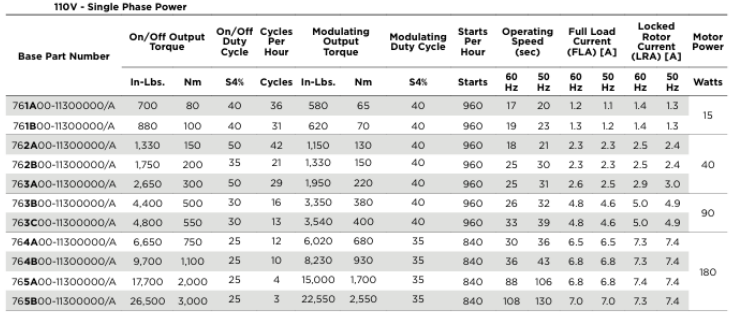

,pagina,caracteres_texto_nativo,imagenes,ancho_pt,alto_pt
0,1,0,2,612.0,792.0
1,2,0,2,612.0,792.0
2,3,0,1,612.0,792.0
3,4,0,1,612.0,792.0


SHA-256: 4c28023929183df8e2a763e759cc84572b44604b30837a21e22c1166f88267e0


In [2]:
import pymupdf
from scripts.ocr_lab import PDF, sha256, LAYOUTS
with pymupdf.open(PDF) as doc:
    inventory = pd.DataFrame([{"pagina": i+1, "caracteres_texto_nativo": len(p.get_text().strip()),
                               "imagenes": len(p.get_images()), "ancho_pt": p.rect.width,
                               "alto_pt": p.rect.height} for i,p in enumerate(doc)])
    pix = doc[0].get_pixmap(dpi=120, alpha=False)
    from PIL import Image as PILImage
    import io
    display(PILImage.open(io.BytesIO(pix.tobytes("png"))).crop((130,235,865,550)))
display(inventory)
print("SHA-256:", sha256(PDF))

## 2. Protocolo antes de mirar los resultados
- Mismas cuatro páginas, 300 DPI y CPU para los tres motores. Tiempos de carga separados de inferencia; una medición, sin pretender un benchmark de latencia robusto.
- Misma geometría manual para las siete tablas, incluyendo potencia combinada y bloque N/A. Ver `LAYOUTS` en `scripts/ocr_lab.py`. No se usan respuestas esperadas para reconstruir.
- Comparación por **tabla/fila/campo**, no por el código detectado: perder un código no elimina su fila de la evaluación.
- Normalización limitada a espacios, mayúsculas y formato numérico. No corregir O→0 ni cifras por intuición.
- Código: coincidencia completa; cifras: valor exacto en su celda y unidad/servicio/frecuencia del encabezado; N/A: reconocimiento explícito. Los vacíos estructurales no cuentan como aciertos gratuitos.
- Selección: menos celdas desiguales; desempate por filas completas y tiempo. Se miden aparte los asteriscos CSA.
- La referencia visual de 68 filas es **provisional y falible**. Esto mide coincidencia contra ella; no certifica exactitud independiente global. Los textos/notas originales se conservan, pero su transcripción semántica completa queda fuera de esta métrica.
- No se usan confidencias como si fueran exactitud ni se comparan entre motores.
- El mejor resultado puede seguir siendo insuficiente para importar a PostgreSQL. No habrá reparación automática de discrepancias.

In [3]:
from scripts.ocr_evaluate import benchmark, evaluate
# Por defecto ejecuta los tres motores y crea evidencia nueva.
# Solo para reabrir una ejecución terminada: SERIE76_BENCHMARK_DIR=<carpeta>.
existing = os.environ.get("SERIE76_BENCHMARK_DIR")
if existing:
    run_dir = Path(existing).resolve()
    metrics, details, selection = evaluate(run_dir)
else:
    run_dir, metrics, details, selection = benchmark()
display(metrics.round(3))
print("Evidencia:", run_dir)
print("Seleccionado dentro de este ensayo:", selection["engine"])

,engine,cells,exact,errors,complete_rows,inference_seconds,load_seconds,code_exact,code_total,numeric_exact,numeric_total,status_exact,status_total,csa_markers_exact
0,rapidocr,941,935,6,63,64.038,1.876,68,68,863,869,4,4,5
1,easyocr,942,714,228,12,463.106,15.003,13,68,701,869,0,4,0
2,tesseract,944,692,252,12,13.231,0.191,30,68,662,869,0,4,0


Evidencia: C:\Users\nrir\Desktop\dev\serie76-assistant\data\ocr\benchmark-20261103T015356917766Z
Seleccionado dentro de este ensayo: rapidocr


## 3. Errores concretos y distribución por tabla
Las celdas combinadas generan observaciones relacionadas: el conteo de celdas no es una muestra estadística independiente.

In [4]:
display(details.groupby(["engine", "source_table", "kind"]).exact.agg(["sum","count"]).reset_index())
errors = details[~details.exact]
display(errors[["engine","source_table","source_row","field","raw_text","expected","actual"]].head(35))
winner_errors = errors[errors.engine == selection["engine"]]
print("Discrepancias del seleccionado:", len(winner_errors))
display(winner_errors[["source_table","source_row","field","raw_text","expected","actual"]].head(25))

,engine,source_table,kind,sum,count
0,easyocr,p1_t1,annotation,11,11
1,easyocr,p1_t1,code,0,11
2,easyocr,p1_t1,numeric,102,165
3,easyocr,p1_t2,annotation,11,16
4,easyocr,p1_t2,code,0,16
...,...,...,...,...,...
63,tesseract,p4_t1,code,10,10
64,tesseract,p4_t1,numeric,133,150
65,tesseract,p4_t2,annotation,10,10
66,tesseract,p4_t2,code,10,10


,engine,source_table,source_row,field,raw_text,expected,actual
0,tesseract,p1_t1,1,base_part_number,TSIAOO-1Z00000/4.,761A00-11300000/A,TSIAOO-1Z00000/4.
1,tesseract,p1_t1,1,on_off_torque_in_lb,7Oo,7E+2,7OO
2,tesseract,p1_t1,1,on_off_torque_nm,ao,8E+1,AO
6,tesseract,p1_t1,1,modulating_torque_nm,65.,65,65.
9,tesseract,p1_t1,1,operating_time_60hz_s,Fs,17,FS
10,tesseract,p1_t1,1,operating_time_50hz_s,26,2E+1,26
11,tesseract,p1_t1,1,fla_60hz_a,12,1.2,12
12,tesseract,p1_t1,1,fla_50hz_a,11,1.1,11
13,tesseract,p1_t1,1,lra_60hz_a,Led,1.4,LED
14,tesseract,p1_t1,1,lra_50hz_a,13,1.3,13


Discrepancias del seleccionado: 6


,source_table,source_row,field,raw_text,expected,actual
2200,p1_t2,1,on_off_torque_nm,8:0,8E+1,8:0
2318,p1_t2,8,starts_per_hour,8:40,8.4E+2,8:40
2334,p1_t2,9,starts_per_hour,8:40,8.4E+2,8:40
2366,p1_t2,11,starts_per_hour,8:40,8.4E+2,8:40
2488,p2_t1,7,cycles_per_hour,3:2,32,3:2
2490,p2_t1,7,operating_time_60hz_s,3.2,32,3.2


## 4. Configuración operativa, sin declarar los datos validados
Guardamos el motor ganador para una ejecución repetible. La selección no completa ingestión ni autoriza cargar resultados sin revisar.

In [5]:
from scripts.ocr_lab import write_json
import shutil
config_dir = ROOT / "config"
config_dir.mkdir(exist_ok=True)
write_json(config_dir / "ocr.json", selection)
evidence_dir = ROOT / "reports/ocr"
evidence_dir.mkdir(parents=True, exist_ok=True)
for name in ["metrics.csv", "discrepancies.csv", "selection.json", "experiment.json"]:
    source = run_dir / name
    if source.exists():
        shutil.copy2(source, evidence_dir / name)
for engine in ["tesseract", "easyocr", "rapidocr"]:
    shutil.copy2(run_dir / engine / "manifest.json", evidence_dir / f"{engine}_manifest.json")
display(Markdown(f"**Motor seleccionado: {selection['engine']}**. "
                 f"Quedan {len(winner_errors)} discrepancias, incluidas anotaciones. "
                 "Ver reports/ocr/discrepancies.csv; los datos siguen sin validar para producción."))
print("Ejecutar otra vez con:")
print("python scripts/ocr_lab.py --config config/ocr.json --out data/ocr/nueva-ejecucion")

**Motor seleccionado: rapidocr**. Quedan 6 discrepancias, incluidas anotaciones. Ver reports/ocr/discrepancies.csv; los datos siguen sin validar para producción.

Ejecutar otra vez con:
python scripts/ocr_lab.py --config config/ocr.json --out data/ocr/nueva-ejecucion
